**Objectives:**

**Data Preparation:**

● Download and extract the cats vs. dogs dataset.


In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/

In [1]:
!kaggle datasets download -d salader/dogsvscats

Dataset URL: https://www.kaggle.com/datasets/salader/dogsvscats
License(s): unknown
100% 1.06G/1.06G [00:05<00:00, 222MB/s]



In [2]:
import zipfile

zip_ref = zipfile.ZipFile("/content/dogsvscats.zip")
zip_ref.extractall("/content")
zip_ref.close()

● Organize the dataset into a structured directory format suitable for
TensorFlow’s ImageDataGenerator

In [4]:
import tensorflow as tf
import keras
from keras.layers import Conv2D,Dense,Flatten
from keras.models import Sequential

In [5]:
#generators
train_ds = keras.utils.image_dataset_from_directory(
    directory = "/content/train",
    labels="inferred",
    label_mode="int",
    batch_size=32,
    image_size=(256, 256),
)

Found 20000 files belonging to 2 classes.


In [6]:
#generators
test_ds = keras.utils.image_dataset_from_directory(
    directory = "/content/test",
    labels="inferred",
    label_mode="int",
    batch_size=32,
    image_size=(256, 256),
)

Found 5000 files belonging to 2 classes.


● Split the dataset into training and testing sets.

Train-Test Split:

The dataset was already divided into separate training and testing directories. The training images were loaded from the train directory and the testing images were loaded from the test directory using TensorFlow's image_dataset_from_directory() function. The training dataset is used to train the CNN, while the testing dataset is used to evaluate the model's performance on unseen images.

**Data Augmentation and Preprocessing :**

● Implement data augmentation techniques to increase the diversity of the
training dataset, aiding in the model's ability to generalize.

In [7]:
from keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [10]:
train_datagen = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True,
    zoom_range=0.2,
    rescale=1./255
)

In [20]:
train_generator = train_datagen.flow_from_directory(
    "/content/catsvsdogs/train",
    target_size=(256, 256),
    batch_size=32,
    class_mode="categorical"
)

Found 20000 images belonging to 2 classes.


● Normalize the pixel values of the images for optimal model performance.

In [12]:
test_datagen = ImageDataGenerator(
    rescale=1./255
)

In [21]:
test_generator = test_datagen.flow_from_directory(
    "/content/catsvsdogs/test",
    target_size=(256, 256),
    batch_size=32,
    class_mode="categorical",
    shuffle=False
)

Found 5000 images belonging to 2 classes.


**Model Building :**

● Construct a Convolutional Neural Network using TensorFlow and Keras.


In [14]:
from keras.layers import MaxPooling2D,BatchNormalization,Dropout

In [15]:
#architecture
model = Sequential()
model.add(Conv2D(32,kernel_size=(3,3),padding="valid",activation="relu",input_shape=(256,256,3)))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding="valid"))

model.add(Conv2D(64,kernel_size=(3,3),padding="valid",activation="relu"))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding="valid"))

model.add(Conv2D(128,kernel_size=(3,3),padding="valid",activation="relu"))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding="valid"))

model.add(Flatten())

model.add(Dense(128,activation="relu"))
model.add(Dropout(0.2))
model.add(Dense(64,activation="relu"))
model.add(Dropout(0.2))
model.add(Dense(1,activation="sigmoid"))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


● The model should contain multiple convolutional layers, pooling layers, and
fully connected layers.

CNN Architecture:

The CNN model consists of three convolutional layers with 32, 64, and 128 filters respectively. Each convolutional layer is followed by batch normalization and a max-pooling layer. The extracted features are flattened and passed through two fully connected Dense layers containing 128 and 64 neurons. Dropout layers are included to reduce overfitting. Finally, a single-neuron output layer with sigmoid activation is used for binary classification of cats and dogs.

**Training :**

● Compile the model and train it on the prepared dataset.

In [16]:
model.compile(loss="binary_crossentropy",optimizer="adam",metrics=["accuracy"])

● Utilize categorical cross entropy as the loss function and stochastic
gradient descent as the optimizer.


In [22]:
model = Sequential()
model.add(Conv2D(32,kernel_size=(3,3),padding="valid",activation="relu",input_shape=(256,256,3)))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding="valid"))

model.add(Conv2D(64,kernel_size=(3,3),padding="valid",activation="relu"))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding="valid"))

model.add(Conv2D(128,kernel_size=(3,3),padding="valid",activation="relu"))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding="valid"))

model.add(Flatten())

model.add(Dense(128,activation="relu"))
model.add(Dropout(0.2))
model.add(Dense(64,activation="relu"))
model.add(Dropout(0.2))
model.add(Dense(2, activation="softmax"))

In [23]:
model.compile(
    optimizer="sgd",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

● Train the model for a sufficient number of epochs to achieve good
performance.


In [24]:
history = model.fit(
    train_generator,
    epochs=20,
    validation_data=test_generator
)

Epoch 1/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 369s 569ms/step - accuracy: 0.6080 - loss: 0.6735 - val_accuracy: 0.6844 - val_loss: 0.6082
Epoch 2/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 351s 561ms/step - accuracy: 0.6754 - loss: 0.6022 - val_accuracy: 0.6662 - val_loss: 0.6098
Epoch 3/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 351s 561ms/step - accuracy: 0.6895 - loss: 0.5824 - val_accuracy: 0.6788 - val_loss: 0.5938
Epoch 4/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 347s 556ms/step - accuracy: 0.7135 - loss: 0.5630 - val_accuracy: 0.7424 - val_loss: 0.5204
Epoch 5/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 343s 549ms/step - accuracy: 0.7243 - loss: 0.5463 - val_accuracy: 0.7498 - val_loss: 0.4977
Epoch 6/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 340s 545ms/step - accuracy: 0.7370 - loss: 0.5268 - val_accuracy: 0.7574 - val_loss: 0.4884
Epoch 7/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 340s 543ms/step - accuracy: 0.7414 - loss: 0.5181 - val_accuracy: 0.7428 - val_loss: 0.5075
Epoch 8/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 343s 549ms/step - accuracy: 0.7526 -

**Evaluation:**

● Evaluate the model's performance on the validation set during training to
monitor for overfitting.

In [25]:
import matplotlib.pyplot as plt

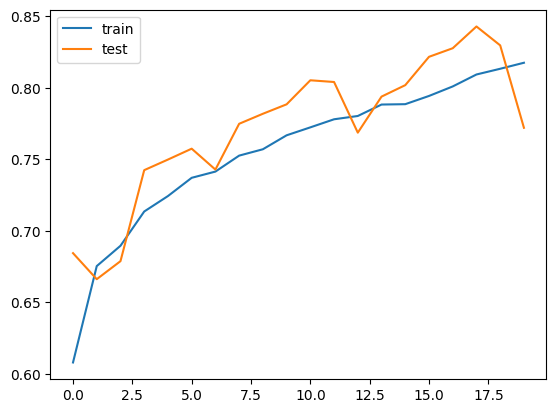

In [26]:
plt.plot(history.history["accuracy"],label="train")
plt.plot(history.history["val_accuracy"],label="test")
plt.legend()
plt.show()

● After training, assess the model's accuracy and make predictions on the
test set.

In [28]:
test_loss, test_accuracy = model.evaluate(test_generator)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

157/157 ━━━━━━━━━━━━━━━━━━━━ 12s 75ms/step - accuracy: 0.7720 - loss: 0.4618
Test Loss: 0.4617545008659363
Test Accuracy: 0.7720000147819519


In [29]:
predictions = model.predict(test_generator)

157/157 ━━━━━━━━━━━━━━━━━━━━ 16s 93ms/step


In [30]:
import numpy as np
predicted_classes = np.argmax(predictions, axis=1)

In [31]:
print("Predicted Classes:", predicted_classes[:10])

Predicted Classes: [1 0 0 0 0 0 1 1 1 1]


In [32]:
print("Class Indices:", test_generator.class_indices)

Class Indices: {'cats': 0, 'dogs': 1}


**Prediction:**

● Implement a system to make predictions on new images, categorizing
them as either cat or dog.

● The system should be able to take an image (or a batch of images),
preprocess it, and pass it through the model for prediction.

In [33]:
from tensorflow.keras.utils import load_img, img_to_array
import numpy as np

In [34]:
image_path = "/content/pexels-724211268-33585484.jpg"

In [35]:
img = load_img(image_path, target_size=(256, 256))

In [36]:
img_array = img_to_array(img)


In [37]:
img_array = img_array / 255.0

In [38]:
img_array = np.expand_dims(img_array, axis=0)

In [39]:
prediction = model.predict(img_array)

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


In [40]:
predicted_class = np.argmax(prediction, axis=1)[0]


In [41]:
class_names = ["cat", "dog"]


In [42]:
print("Prediction:", class_names[predicted_class])

Prediction: cat
